# 01 - Donnees et decoupage : lire, cataloguer, decouper sans fuite

Avant tout modele : savoir lire les images (8 / 16 bits, chemins Windows), les ranger dans un
catalogue (une ligne par image, quel que soit le rangement sur le disque), les decouper en
train / val / test SANS fuite (une meme piece des deux cotes rend le test optimiste), et
calculer ce qui en decoule (moyenne / ecart-type, poids des classes).

- Donnees : NEU-CLS (`get_neu_cls.py`), MVTec AD bottle (`get_mvtec_bottle.py`), Magnetic Tile
  (`get_magnetic_tile.py`) ; les groupes de quasi-doublons de Magnetic Tile viennent de
  `recipes/explore/scripts/check_dataset.py --config recipes/explore/configs/magnetic_tile.yaml`
  (sinon la section 6 tourne sans eux).
- Aucun entrainement ; duree : moins d'une minute.

**Dans le fil** : ce notebook approfondit les etapes 2 (Importer et explorer : lire une image),
3 (Cataloguer) et 4 (Decouper), et prepare l'etape 5 (Pretraiter : moyenne et ecart-type du train).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 1. Reglages (etape 1)

In [1]:
import hashlib  # hashlib : empreintes de fichiers (md5) pour reperer les doublons exacts
import re  # re : expressions regulieres (motifs de texte), pour lire groupe et date dans un nom de fichier
from datetime import datetime, timedelta  # datetime : une date ; timedelta : une duree (pour fabriquer des dates)
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : trace de figures (ici la frise du decoupage temporel)
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici les catalogues d'images
from PIL import Image  # PIL (Pillow) : autre lecteur d'images, ici pour lire la taille sans decoder

# decoupages de scikit-learn : en plis qui respectent les groupes, et tirage simple
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

from vtb import viz  # viz : affichage de la toolbox (grilles d'images, comparaisons, histogrammes)

QUICK = True  # True : statistiques sur un echantillon ; False : sur tout le train
DATA_DIR = Path("data/raw/neu_cls_flat")  # un sous-dossier par classe : DATA_DIR/<classe>/<image>
MVTEC_DIR = Path("data/raw/mvtec_bottle")  # jeu MVTec AD (flacons) : arborescence train / test / ground_truth
TILE_DIR = Path("data/raw/magnetic_tile")  # image + masque a cote (meme nom, .png)
# CSV (path, group) des quasi-doublons, produit par recipes/explore check_dataset.py
TILE_GROUPS_CSV = Path("outputs/explore/magnetic_tile/groups.csv")
EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichier acceptees comme images (comparees en minuscules)
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # 15 % validation, 15 % test, le reste (70 %) pour l'entrainement
SEED = 42  # graine du hasard : memes tirages a chaque execution
STATS_IMAGES = 200 if QUICK else 500  # images du train pour la moyenne / l'ecart-type
OUT = Path("outputs/notebooks/01_donnees_decoupage")  # dossier des sorties de ce notebook
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) ; pas d'erreur s'il existe deja
viz.setup_notebook(dpi=80, fmt="jpeg")  # reglage des figures : 80 points par pouce, format jpeg (notebook plus leger)

## 2. Lire une image : une fonction, toutes les situations (etape 2)

Convention de toute la toolbox : une image en memoire est un `numpy.ndarray` (H, W) en gris ou
(H, W, 3) en **RGB**, en uint8 (0-255) ou uint16 (0-65535) CONSERVE. Trois pieges :

- `cv2.imread` renvoie `None` sans erreur sur un chemin Windows avec accents : on lit les octets
  (`np.fromfile`) puis on decode (`cv2.imdecode`), ce qui marche partout ;
- OpenCV lit en BGR : on convertit une fois, a la lecture, pour ne plus y penser ;
- `cv2.IMREAD_UNCHANGED` garde les 16 bits ; le drapeau par defaut les ecrase en 8 bits.

In [2]:
def read_image(path, color="rgb"):  # lit une image ; renvoie un tableau numpy RGB, gris ou tel que stocke, selon color
    """color = rgb (H, W, 3), gray (H, W) ou unchanged (tel que stocke, BGR remis en RGB)."""
    # np.fromfile lit les octets (marche avec les accents) ; imdecode les decode tels quels (IMREAD_UNCHANGED)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible ou corrompue : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si 4 canaux (couleur + transparence alpha) : la transparence est ignoree
        image = image[:, :, :3]  # on garde les 3 canaux de couleur
    if color == "unchanged":  # si on veut l'image telle que stockee (le gris reste gris, le 16 bits reste 16 bits)
        # seule correction : BGR d'OpenCV -> RGB si c'est une image couleur
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image
    if color == "gray":  # si on demande du gris
        # couleur -> gris si besoin (OpenCV range les couleurs en BGR) ; sinon l'image est deja grise
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    # gris : canal recopie 3 fois (3 canaux attendus) ; couleur : BGR d'OpenCV -> RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def write_image(path, image):  # ecrit une image sur le disque (format choisi par l'extension) ; ne renvoie rien
    """Ecriture symetrique (cv2.imencode + tofile) : chemins avec accents, RGB -> BGR, 16 bits conserves en PNG / TIFF."""
    path = Path(path)  # accepte un texte ou un Path
    path.parent.mkdir(parents=True, exist_ok=True)  # cree le dossier de destination s'il manque
    # encode en memoire au format de l'extension (.png...) ; couleur RGB -> BGR, l'ordre d'OpenCV
    ok, buffer = cv2.imencode(path.suffix, cv2.cvtColor(image, cv2.COLOR_RGB2BGR) if image.ndim == 3 else image)
    if not ok:  # si l'encodage a echoue (format inconnu, type non gere)
        raise ValueError(f"encodage impossible : {path}")  # on arrete avec un message clair
    buffer.tofile(str(path))  # ecrit les octets dans le fichier (marche avec les accents, contrairement a cv2.imwrite)


first = sorted((DATA_DIR / "crazing").iterdir())[0]  # premier fichier (ordre alphabetique) du dossier de la classe crazing
for mode in ("unchanged", "gray", "rgb"):  # pour chacun des trois modes de lecture
    image = read_image(first, mode)  # lit la meme image dans ce mode
    # forme, type et plage de valeurs obtenus
    print(f"{mode:9s} -> forme {image.shape}, type {image.dtype}, min {image.min()}, max {image.max()}")
with Image.open(first) as handle:  # taille sans decoder l'image (lecture de l'en-tete)
    # PIL donne (largeur, hauteur), alors que numpy donne (hauteur, largeur)
    print("taille lue dans l'en-tete (largeur, hauteur) :", handle.size)

unchanged -> forme (200, 200), type uint8, min 60, max 255
gray      -> forme (200, 200), type uint8, min 60, max 255
rgb       -> forme (200, 200, 3), type uint8, min 60, max 255
taille lue dans l'en-tete (largeur, hauteur) : (200, 200)


### Une image 16 bits, dans un dossier avec accents

Beaucoup de cameras industrielles (thermique, rayons X, cameras 12 bits) livrent du 16 bits qui
n'occupe qu'une partie de la dynamique. Ici on fabrique une telle image (valeurs 0-16 000 sur
65 535) : divisee par 65 535 elle parait noire, un etirement aux percentiles la rend lisible.
Pour le reseau, on garde la division par la valeur max du TYPE (rien d'invente) ou on choisit un
etirement fixe ; jamais un etirement image par image sans le dire (le contraste deviendrait une
information).

outputs/notebooks/01_donnees_decoupage/données été/pièce_16bits.png -> uint16 (200, 200) max 15056 | identique : True


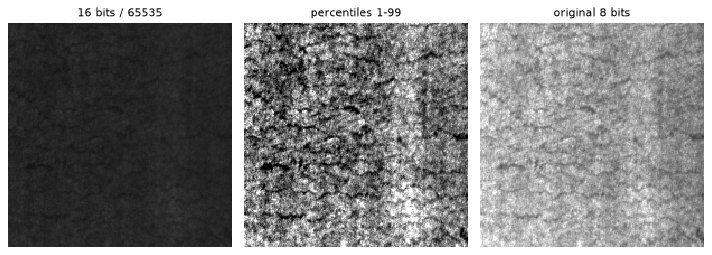

In [3]:
gray8 = read_image(first, "gray")  # l'image en gris 8 bits (valeurs 0-255)
# rampe de 0 a 3000 sur la largeur ; [None, :] : forme (1, W) pour s'ajouter a chaque ligne
ramp = np.linspace(0, 3000, gray8.shape[1], dtype=np.float32)[None, :]
# image 16 bits fabriquee : gris x 50 + rampe, soit 0 a ~16 000 sur 65 535 possibles
image16 = (gray8.astype(np.float32) * 50 + ramp).astype(np.uint16)
accented = OUT / "donn\u00e9es \u00e9t\u00e9" / "pi\u00e8ce_16bits.png"  # dossier et fichier avec accents et espace
write_image(accented, image16)  # ecrit en PNG, format qui garde les 16 bits
back = read_image(accented, "unchanged")  # relit le fichier tel quel
# type et forme relus ; array_equal : les pixels sont-ils exactement les memes ?
print(accented, "->", back.dtype, back.shape, "max", back.max(), "| identique :", np.array_equal(back, image16))


def to_uint8(image, low=None, high=None):  # image 8 ou 16 bits -> uint8 0-255 pour l'affichage ; low / high = percentiles d'etirement
    """Affichage : division par le max du type, ou etirement entre deux percentiles."""
    data = image.astype(np.float32)  # calcul en nombres a virgule
    # bornes : 0 et le max du type sans percentiles ; sinon les percentiles low et high des pixels
    lo, hi = (0.0, 65535.0 if image.dtype == np.uint16 else 255.0) if low is None else np.percentile(data, [low, high])
    # [lo, hi] -> [0, 1] (clip coupe ce qui depasse) puis 0-255 arrondi ; max(...) evite une division par 0
    return (np.clip((data - lo) / max(hi - lo, 1e-6), 0, 1) * 255 + 0.5).astype(np.uint8)


# cote a cote : division par 65535 (sombre), etirement 1-99 %, original 8 bits
viz.compare({"16 bits / 65535": to_uint8(back), "percentiles 1-99": to_uint8(back, 1, 99), "original 8 bits": gray8}, size=3)

## 3. Le catalogue : un tableau, quel que soit le rangement (etape 3)

Colonnes standard : `path` (seule obligatoire), `label`, `split` (si le rangement l'impose),
`group` (piece, bobine : reste d'un seul cote du decoupage), `timestamp`, `mask_path`. La suite
ne lit plus jamais le disque autrement que par ce tableau.

In [4]:
def list_images(root, extensions=EXTENSIONS):  # liste triee des fichiers images d'un dossier et de ses sous-dossiers
    """Images d'un dossier (recursif), triees : l'ordre du disque differe entre Windows et Linux."""
    # rglob("*") parcourt tout ; on garde les fichiers dont l'extension est acceptee
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in extensions)


def from_class_folders(root):  # catalogue d'un dossier range par classe ; renvoie un DataFrame (path, label)
    """root/<classe>/<image> : le rangement le plus courant."""
    # pour chaque sous-dossier (classe) trie, pour chaque image : {chemin, nom du sous-dossier}
    rows = [{"path": str(p), "label": d.name} for d in sorted(x for x in Path(root).iterdir() if x.is_dir()) for p in list_images(d)]
    return pd.DataFrame(rows)  # une ligne par image


# catalogue depuis un CSV d'etiquettes ; renvoie un DataFrame (path, label)
def from_csv(root, csv_path, path_column="filename", label_column="label"):
    """Un dossier d'images et un CSV (chemin relatif a root, etiquette)."""
    table = pd.read_csv(csv_path)  # lit le CSV dans un tableau pandas
    # chemin complet = root / nom donne par le CSV ; etiquette convertie en texte
    return pd.DataFrame({"path": [str(Path(root) / f) for f in table[path_column]], "label": table[label_column].astype(str)})


def from_split_folders(root):  # catalogue d'un dossier deja decoupe en train / val / test ; renvoie un DataFrame avec split
    """root/{train,val,test}/<classe>/<image> : le decoupage fourni est garde (colonne split)."""
    # pour chaque partie presente : catalogue de ses classes + colonne split a son nom
    frames = [from_class_folders(Path(root) / s).assign(split=s) for s in ("train", "val", "test") if (Path(root) / s).is_dir()]
    return pd.concat(frames, ignore_index=True)  # colle les tableaux les uns sous les autres, lignes renumerotees


def from_mvtec(root):  # catalogue du jeu MVTec AD (normal / defaut, masques) ; renvoie un DataFrame
    """MVTec AD : train/good, test/<type>, ground_truth/<type>/<nom>_mask.png."""
    root = Path(root)  # accepte un texte ou un Path
    rows = [  # d'abord l'entrainement : images toutes normales (good), sans masque
        {"path": str(p), "label": "good", "defect_type": "good", "split": "train", "mask_path": ""}  # une ligne par image normale
        for p in list_images(root / "train" / "good")  # pour chaque image de train/good
    ]
    # pour chaque sous-dossier du test (good ou un type de defaut), trie
    for type_dir in sorted(d for d in (root / "test").iterdir() if d.is_dir()):
        for p in list_images(type_dir):  # pour chaque image de ce type
            # chemin du masque attendu : ground_truth/<type>/<nom>_mask.png
            mask = root / "ground_truth" / type_dir.name / f"{p.stem}_mask.png"
            label = "good" if type_dir.name == "good" else "defect"  # etiquette binaire : good, ou defect pour tout type de defaut
            rows.append(  # ajoute la ligne de cette image de test
                {  # dictionnaire de la ligne
                    "path": str(p),  # chemin de l'image
                    "label": label,  # good ou defect
                    "defect_type": type_dir.name,  # type precis (nom du sous-dossier)
                    "split": "test",  # MVTec fournit deja le decoupage
                    "mask_path": str(mask) if mask.exists() else "",  # masque s'il existe (les images good n'en ont pas)
                }
            )
    return pd.DataFrame(rows)  # une ligne par image


# catalogue image + masque (Magnetic Tile) ; renvoie un DataFrame avec has_defect
def from_image_mask(root, extensions=(".jpg",), mask_suffix=""):
    """Image + masque de meme nom a cote (.png) ; label = premier sous-dossier ; has_defect d'apres le masque."""
    rows = []  # lignes du catalogue, remplies dans la boucle
    for p in list_images(root, set(extensions)):  # pour chaque image (.jpg par defaut : les masques .png sont exclus)
        mask = p.parent / f"{p.stem}{mask_suffix}.png"  # masque a cote : meme nom, suffixe eventuel, extension .png
        relative = p.relative_to(root)  # chemin relatif a root (pour lire le sous-dossier)
        has_defect = bool((read_image(mask, "gray") > 127).any())  # defaut si au moins un pixel du masque est clair (> 127)
        # classe = premier sous-dossier ; image a la racine : defect ou free selon le masque
        label = relative.parts[0] if len(relative.parts) > 1 else ("defect" if has_defect else "free")
        rows.append({"path": str(p), "label": label, "mask_path": str(mask), "has_defect": has_defect})  # ajoute la ligne
    return pd.DataFrame(rows)  # une ligne par image


neu = from_class_folders(DATA_DIR)  # catalogue NEU-CLS
# nombre d'images et effectif par classe
print("NEU-CLS (dossier par classe) :", len(neu), "images", neu["label"].value_counts().sort_index().to_dict())

# Un CSV d'etiquettes (le cas d'une base de production exportee) : on en ecrit un, on le relit.
labels_csv = OUT / "labels.csv"  # chemin du CSV d'etiquettes a fabriquer
# ecrit un CSV (filename relatif a DATA_DIR, label), comme un export de base de production
neu.assign(filename=[str(Path(p).relative_to(DATA_DIR)) for p in neu["path"]])[["filename", "label"]].to_csv(labels_csv, index=False)
from_csv_catalog = from_csv(DATA_DIR, labels_csv)  # relit ce CSV en catalogue
# equals : le catalogue relu est-il exactement celui d'origine ?
print("depuis le CSV :", len(from_csv_catalog), "lignes, identique :", from_csv_catalog.equals(neu[["path", "label"]]))

mvtec = from_mvtec(MVTEC_DIR)  # catalogue MVTec bottle
print("\nMVTec bottle :")  # titre ("\n" = saut de ligne)
print(pd.crosstab(mvtec["defect_type"], mvtec["split"]))  # nombre d'images par type de defaut et par partie

tiles = from_image_mask(TILE_DIR)  # catalogue Magnetic Tile (lit chaque masque : quelques secondes)
print("\nMagnetic Tile (image + masque) :", len(tiles), "images")  # nombre d'images
# par dossier : nombre d'images et nombre avec defaut (somme des True), colonnes renommees
print(tiles.groupby("label")["has_defect"].agg(["count", "sum"]).rename(columns={"count": "images", "sum": "avec_defaut"}))

NEU-CLS (dossier par classe) : 1800 images {'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted': 300, 'rolled': 300, 'scratches': 300}
depuis le CSV : 1800 lignes, identique : True

MVTec bottle :
split          test  train
defect_type               
broken_large     20      0
broken_small     22      0
contamination    21      0
good             20    209



Magnetic Tile (image + masque) : 1344 images
             images  avec_defaut
label                           
MT_Blowhole     115          115
MT_Break         85           85
MT_Crack         57           57
MT_Fray          32           32
MT_Free         952            0
MT_Uneven       103           99


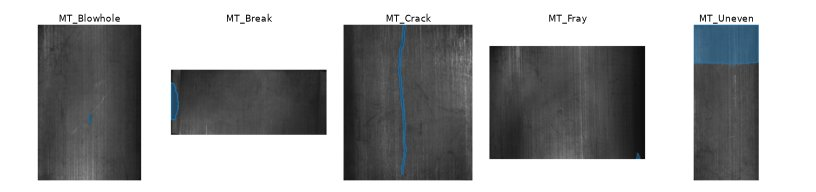

In [5]:
picked = tiles[tiles["has_defect"]].groupby("label").head(1)  # une image avec defaut par classe (head(1) = la premiere de chaque groupe)
viz.grid(  # grille d'images
    [  # liste des images a afficher
        # masque binarise (0 / 1) superpose en couleur a l'image en gris
        viz.overlay_mask(read_image(p, "gray"), (read_image(m, "gray") > 127).astype(np.uint8))
        for p, m in zip(picked["path"], picked["mask_path"])  # pour chaque couple (image, masque) choisi
    ],
    picked["label"].tolist(),  # legendes : la classe
    ncols=5,  # 5 images par ligne
)

## 4. Controler le catalogue avant de decouper (etape 3)

Images illisibles, tailles heterogenes, doublons EXACTS (meme contenu sous deux noms : s'ils
tombent dans train et test, le test triche), equilibre des classes. Les quasi-doublons
(meme piece sous deux expositions) demandent une mesure de similarite : notebook 05.

illisibles : 0
tailles : {'200x200': 1800} | types : {'uint8': 1800}
doublons exacts : 2 images


Magnetic Tile, tailles differentes : 1225 (les reseaux demandent un redimensionnement)
poids de classe (inverses des effectifs) : {'crazing': 1.0, 'inclusion': 1.0, 'patches': 1.0, 'pitted': 1.0, 'rolled': 1.0, 'scratches': 1.0}


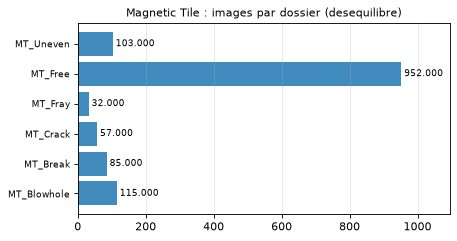

In [6]:
def file_md5(path):  # empreinte md5 : deux fichiers au contenu identique ont la meme ; renvoie un texte
    return hashlib.md5(Path(path).read_bytes()).hexdigest()  # lit tous les octets et calcule l'empreinte en hexadecimal


def inspect_catalog(catalog):  # controle chaque image ; renvoie le catalogue + colonnes readable, shape, dtype, md5
    rows = []  # une ligne de resultats par image
    for p in catalog["path"]:  # pour chaque chemin du catalogue
        try:  # on tente la lecture
            image = read_image(p, "unchanged")  # lecture sans conversion, pour voir le vrai type
            # lisible : forme ecrite "200x200", type de pixel, empreinte
            rows.append({"readable": True, "shape": "x".join(map(str, image.shape)), "dtype": str(image.dtype), "md5": file_md5(p)})
        except ValueError:  # si read_image a signale une image illisible
            # illisible : seuls l'indicateur et l'empreinte sont remplis
            rows.append({"readable": False, "shape": "", "dtype": "", "md5": file_md5(p)})
    # colle les nouvelles colonnes a droite du catalogue (axis=1), lignes alignees
    return pd.concat([catalog.reset_index(drop=True), pd.DataFrame(rows)], axis=1)


neu_checked = inspect_catalog(neu)  # controle du catalogue NEU-CLS
print("illisibles :", int((~neu_checked["readable"]).sum()))  # ~ inverse les booleens : on compte les illisibles
# tailles et types rencontres, avec leur nombre
print("tailles :", neu_checked["shape"].value_counts().to_dict(), "| types :", neu_checked["dtype"].value_counts().to_dict())
# lignes dont l'empreinte apparait plusieurs fois (keep=False : toutes les copies)
duplicates = neu_checked[neu_checked.duplicated("md5", keep=False)]
print("doublons exacts :", len(duplicates), "images")  # nombre d'images concernees
tiles_checked = inspect_catalog(tiles)  # controle du catalogue Magnetic Tile
# nombre de tailles differentes
print("Magnetic Tile, tailles differentes :", tiles_checked["shape"].nunique(), "(les reseaux demandent un redimensionnement)")

counts = neu["label"].value_counts().sort_index()  # effectif par classe
weights = len(neu) / (len(counts) * counts)  # total / (nb classes x effectif) : une classe rare pese plus dans la perte (perte ponderee)
print("poids de classe (inverses des effectifs) :", weights.round(3).to_dict())  # poids arrondis a 3 decimales
# barres : nombre d'images par dossier de Magnetic Tile, pour voir le desequilibre
viz.per_class_bars(tiles["label"].value_counts().sort_index().to_dict(), title="Magnetic Tile : images par dossier (desequilibre)")

## 5. Decoupage stratifie (le cas par defaut ; etape 4)

On preleve le test (15 %) puis la validation (15 % du total, donc 0,15 / 0,85 du reste), en
gardant les proportions de classes (`stratify`). La graine fixe le tirage : le meme
`split.csv` que la recette de classification, au caractere pres.

In [7]:
def can_stratify(labels, fraction):  # True si un tirage stratifie est possible pour cette fraction
    counts = labels.value_counts()  # effectif de chaque classe
    # au moins 2 classes, 2 images par classe, et assez d'images tirees pour une par classe
    return len(counts) > 1 and counts.min() >= 2 and fraction * len(labels) >= len(counts)


def holdout_random(index, labels, fraction, seed):  # tire une fraction des lignes au hasard (stratifie si possible) ; renvoie leurs indices
    # stratification si les etiquettes existent et le permettent, sinon tirage simple
    stratify = labels if labels is not None and can_stratify(labels, fraction) else None
    # train_test_split coupe les indices en deux ; on garde la partie tiree (held)
    _, held = train_test_split(index, test_size=fraction, stratify=stratify, random_state=seed)
    return pd.Index(held)  # indices sous forme d'Index pandas


# decoupage stratifie complet ; renvoie une copie du catalogue avec la colonne split
def split_stratified(catalog, val_fraction, test_fraction, seed):
    catalog = catalog.copy().reset_index(drop=True)  # copie (l'original reste intact), lignes renumerotees de 0 a N-1
    labels = catalog["label"].astype(str)  # etiquettes en texte
    catalog["split"] = "train"  # tout le monde en train au depart
    catalog.loc[holdout_random(catalog.index, labels, test_fraction, seed), "split"] = "test"  # tire le test et le marque
    rest = catalog[catalog["split"] == "train"]  # les lignes restantes
    # tire la validation dans le reste, a la fraction corrigee (0,15 / 0,85)
    val = holdout_random(rest.index, labels[rest.index], val_fraction / (1 - test_fraction), seed)
    catalog.loc[val, "split"] = "val"  # marque la validation
    return catalog  # catalogue decoupe


neu_split = split_stratified(neu, VAL_FRACTION, TEST_FRACTION, SEED)  # decoupage stratifie de NEU-CLS
neu_split["group"] = neu_split["path"]  # sans groupe connu, chaque image est son propre groupe
# enregistre le decoupage (memes colonnes que la recette)
neu_split[["path", "label", "group", "split"]].to_csv(OUT / "split.csv", index=False)
print(pd.crosstab(neu_split["label"], neu_split["split"], margins=True))  # tableau croise classes x parties, avec totaux

split      test  train  val   All
label                            
crazing      45    210   45   300
inclusion    45    210   45   300
patches      45    210   45   300
pitted       45    210   45   300
rolled       45    210   45   300
scratches    45    210   45   300
All         270   1260  270  1800


## 6. Decoupage groupe : quand plusieurs images viennent de la meme source (etape 4)

Une piece photographiee trois fois, une bobine decoupee en 50 images, la meme tuile sous
plusieurs expositions : si ces images tombent des deux cotes, le modele est teste sur ce qu'il
a deja vu. Toutes les images d'un groupe doivent rester du meme cote.

Le groupe vient d'une regex sur le nom de fichier (`^(C\d+)_` donne la bobine de
`C1234_cam2_0007.png`), d'un CSV (numero de piece, groupes de quasi-doublons), ou de la base.

In [8]:
pattern = re.compile(r"^(C\d+)_")  # motif : au debut du nom, C suivi de chiffres puis _ ; les parentheses capturent la bobine
for name in ["C1234_cam2_0007.png", "C1234_cam1_0008.png", "C0042_cam2_0001.png"]:  # pour trois noms de fichiers d'exemple
    print(name, "-> groupe", pattern.search(name).group(1))  # group(1) : le texte capture par les parentheses

if TILE_GROUPS_CSV.exists():  # si le fichier des quasi-doublons a ete calcule
    # serie path -> numero de groupe (texte) ; keep_default_na=False : "NA" reste du texte
    table = pd.read_csv(TILE_GROUPS_CSV, keep_default_na=False).set_index("path")["group"].astype(str)
    tiles["group"] = [table.get(p, p) for p in tiles["path"]]  # groupe de chaque image ; une image absente du CSV forme son propre groupe
else:  # sinon (pas de CSV)
    tiles["group"] = tiles["path"]  # chaque image est son propre groupe
sizes = tiles.groupby("group").size()  # nombre d'images par groupe
# nombre d'images, de groupes, et de groupes de plusieurs images
print(f"\nMagnetic Tile : {len(tiles)} images, {tiles['group'].nunique()} groupes ; {int((sizes > 1).sum())} groupes de plusieurs images")


def crossing_groups(catalog):  # compte les groupes presents dans plusieurs parties ; renvoie un entier (0 = aucune fuite)
    """Nombre de groupes presents dans plusieurs sous-ensembles (0 = aucune fuite)."""
    spread = catalog.groupby("group")["split"].nunique()  # pour chaque groupe, nombre de parties differentes ou il apparait
    return int((spread > 1).sum())  # groupes presents dans plus d'une partie


naive = split_stratified(tiles, 0.15, 0.2, SEED)  # decoupage stratifie qui ignore les groupes (15 % val, 20 % test)
print("decoupage stratifie simple : groupes coupes en deux =", crossing_groups(naive))  # nombre de groupes coupes : la fuite a eviter

C1234_cam2_0007.png -> groupe C1234
C1234_cam1_0008.png -> groupe C1234
C0042_cam2_0001.png -> groupe C0042

Magnetic Tile : 1344 images, 1087 groupes ; 161 groupes de plusieurs images
decoupage stratifie simple : groupes coupes en deux = 92


`StratifiedGroupKFold` de scikit-learn fait des plis qui ne coupent aucun groupe tout en
equilibrant les classes ; avec n plis, un pli fait environ 1/n du jeu. On prend le premier pli de
n = round(1 / fraction) comme test, puis la meme chose dans le reste pour la validation. La
fraction obtenue est approximative : c'est le prix des groupes entiers.

In [9]:
def holdout_grouped(frame, fraction, seed):  # tire environ une fraction des lignes sans couper de groupe ; renvoie leurs indices
    n_splits = max(2, round(1 / fraction))  # nombre de plis = 1 / fraction (au moins 2) : un pli ~ la fraction voulue
    if frame["group"].nunique() < n_splits:  # s'il y a moins de groupes que de plis
        # impossible : on refuse avec un message clair
        raise ValueError(f"{frame['group'].nunique()} groupes : trop peu pour prelever {fraction:.0%} sans couper de groupe")
    # decoupeur en plis : groupes entiers, classes equilibrees, ordre melange avec la graine
    folds = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    # premier pli seulement : held = positions des lignes de ce pli
    _, held = next(folds.split(frame, frame["label"].astype(str), groups=frame["group"]))
    return frame.index[held]  # positions -> etiquettes d'index du tableau


# decoupage groupe complet ; renvoie une copie du catalogue avec la colonne split
def split_grouped(catalog, val_fraction, test_fraction, seed):
    catalog = catalog.copy().reset_index(drop=True)  # copie, lignes renumerotees de 0 a N-1
    catalog["split"] = "train"  # tout le monde en train au depart
    catalog.loc[holdout_grouped(catalog, test_fraction, seed), "split"] = "test"  # tire le test (groupes entiers) et le marque
    rest = catalog[catalog["split"] == "train"]  # les lignes restantes
    # tire la validation dans le reste (groupes entiers), a la fraction corrigee
    catalog.loc[holdout_grouped(rest, val_fraction / (1 - test_fraction), seed), "split"] = "val"
    return catalog  # catalogue decoupe


tiles_split = split_grouped(tiles, 0.15, 0.2, SEED)  # decoupage groupe de Magnetic Tile (15 % val, 20 % test)
print("decoupage groupe : groupes coupes en deux =", crossing_groups(tiles_split))  # doit afficher 0
# proportions obtenues (approximatives : les groupes sont entiers)
print(pd.crosstab(tiles_split["label"], tiles_split["split"], margins=True))
tiles_split.to_csv(OUT / "tile_split.csv", index=False)  # enregistre ce decoupage

decoupage groupe : groupes coupes en deux = 0
split        test  train  val   All
label                              
MT_Blowhole    23     73   19   115
MT_Break       17     54   14    85
MT_Crack       11     37    9    57
MT_Fray         7     20    5    32
MT_Free       190    610  152   952
MT_Uneven      21     66   16   103
All           269    860  215  1344


## 7. Decoupage temporel : tester sur la periode la plus recente (etape 4)

En production, le modele voit des images posterieures a son entrainement (usure d'un rouleau,
nouvel eclairage, autre fournisseur). Le decoupage temporel mesure cette tenue dans le temps :
le passe pour entrainer, le plus recent pour tester, sans couper aucun groupe.

Exemple sur un catalogue fictif (60 bobines sur 60 jours, date et bobine lues dans le nom avec une
regex a groupes nommes `Y`, `m`, `d`).

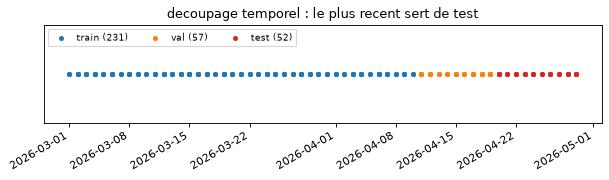

groupes coupes : 0


In [10]:
rng = np.random.default_rng(SEED)  # generateur de hasard numpy a graine fixe
names = []  # noms de fichiers fictifs
for coil in range(60):  # pour chacune des 60 bobines
    day = datetime(2026, 3, 1) + timedelta(days=coil)  # une bobine par jour a partir du 1er mars 2026
    for k in range(int(rng.integers(3, 9))):  # de 3 a 8 images par bobine (integers : borne haute exclue)
        names.append(f"C{1000 + coil}_{day:%Y%m%d}_{k:03d}.png")  # nom du type C1000_20260301_000.png
# catalogue fictif : classe tiree au hasard (60 % ok, 25 % rayure, 15 % inclusion)
fictive = pd.DataFrame({"path": names, "label": rng.choice(["ok", "rayure", "inclusion"], size=len(names), p=[0.6, 0.25, 0.15])})
stamp = re.compile(r"_(?P<Y>\d{4})(?P<m>\d{2})(?P<d>\d{2})_")  # motif de date _AAAAMMJJ_ avec des groupes nommes Y, m, d
# date lue dans chaque nom : m["Y"] = texte capture par le groupe Y, converti en nombre
fictive["timestamp"] = [datetime(int(m["Y"]), int(m["m"]), int(m["d"])) for m in map(stamp.search, fictive["path"])]
fictive["group"] = [pattern.search(n).group(1) for n in fictive["path"]]  # groupe = bobine, lue avec le motif de la section precedente


def holdout_temporal(frame, fraction):  # prend les groupes les plus recents jusqu'a la fraction voulue ; renvoie leurs indices
    """Les groupes les plus recents (date de leur premiere image) jusqu'a la fraction demandee."""
    start = frame.groupby("group")["timestamp"].min().sort_values()  # date de debut de chaque groupe, triee du plus ancien au plus recent
    sizes = frame.groupby("group").size().reindex(start.index)  # nombre d'images de chaque groupe, dans le meme ordre
    target, taken, held = fraction * len(frame), 0, []  # nombre d'images vise, nombre deja pris, groupes retenus
    for group in reversed(start.index):  # pour chaque groupe, du plus recent au plus ancien
        if taken >= target:  # si on a deja assez d'images
            break  # on s'arrete
        held.append(group)  # on retient ce groupe
        taken += sizes[group]  # et on compte ses images
    return frame.index[frame["group"].isin(held)]  # indices des lignes dont le groupe a ete retenu


fictive["split"] = "train"  # tout le monde en train au depart
fictive.loc[holdout_temporal(fictive, TEST_FRACTION), "split"] = "test"  # les bobines les plus recentes vont en test
rest = fictive[fictive["split"] == "train"]  # les lignes restantes
fictive.loc[holdout_temporal(rest, VAL_FRACTION / (1 - TEST_FRACTION)), "split"] = "val"  # les plus recentes du reste vont en validation
fig, ax = plt.subplots(figsize=(9, 1.8))  # figure de 9 x 1,8 pouces avec un seul graphique (ax)
for name, color in (("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")):  # pour chaque partie, avec sa couleur
    part = fictive[fictive["split"] == name]  # les images de cette partie
    # un point par image, place a sa date, tous sur la meme ligne (y = 0)
    ax.scatter(part["timestamp"], np.zeros(len(part)), s=12, color=color, label=f"{name} ({len(part)})")
ax.set_yticks([])  # pas de graduations verticales (l'axe y ne veut rien dire ici)
ax.legend(ncol=3, loc="upper left", fontsize=8)  # legende sur 3 colonnes, en haut a gauche
ax.set_title("decoupage temporel : le plus recent sert de test")  # titre du graphique
fig.autofmt_xdate()  # incline les dates pour qu'elles ne se chevauchent pas
plt.show()  # affiche la figure
print("groupes coupes :", crossing_groups(fictive))  # doit afficher 0

## 8. Validation croisee (facultatif ; etape 4)

Sur un petit jeu, une seule validation est bruitee : on fait k plis sur train + val (le test
reste a part, `fold = -1`), groupes respectes. Un modele par pli ; on rapporte la moyenne et
l'ecart.

In [11]:
def assign_folds(catalog, n_folds, seed):  # repartit train + val en plis respectant les groupes ; renvoie une copie avec la colonne fold
    catalog = catalog.copy()  # copie : l'original reste intact
    catalog["fold"] = -1  # -1 = hors validation croisee (le test)
    dev = catalog[catalog["split"] != "test"]  # images de developpement : tout sauf le test
    # decoupeur en plis : groupes entiers, classes equilibrees
    folds = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    # pour chaque pli k : held = positions des images de ce pli dans dev
    for k, (_, held) in enumerate(folds.split(dev, dev["label"].astype(str), groups=dev["group"])):
        catalog.loc[dev.index[held], "fold"] = k  # ces images recoivent le numero de pli k
    return catalog  # catalogue avec la colonne fold


folded = assign_folds(tiles_split, 5, SEED)  # 5 plis sur le decoupage groupe de Magnetic Tile
print(pd.crosstab(folded["label"], folded["fold"]))  # nombre d'images par classe et par pli

fold          -1    0    1    2    3    4
label                                    
MT_Blowhole   23   19   19   18   18   18
MT_Break      17   14   13   14   14   13
MT_Crack      11    9    9    9   10    9
MT_Fray        7    5    5    5    5    5
MT_Free      190  152  153  153  152  152
MT_Uneven     21   16   16   16   17   17


## 9. Controle des fuites : refuser un decoupage dangereux (etape 4)

A executer apres CHAQUE decoupage (et dans le script de production) : chemin en double,
sous-ensemble inconnu ou vide, groupe coupe en deux ; en anomalies, aucune image defectueuse dans
train / val.

In [12]:
def check_no_leakage(catalog, normal_only_train=False):  # verifie qu'un decoupage n'a pas de fuite ; leve une erreur sinon, ne renvoie rien
    if not catalog["path"].is_unique:  # si un chemin apparait deux fois
        raise ValueError("des images apparaissent deux fois dans le catalogue")  # refus
    unknown = set(catalog["split"]) - {"train", "val", "test"}  # valeurs de split autres que train / val / test (difference d'ensembles)
    if unknown:  # s'il y en a
        raise ValueError(f"valeurs de split inconnues : {sorted(unknown)}")  # refus
    if not (catalog["split"] == "test").any():  # s'il n'y a aucune image de test
        raise ValueError("aucune image de test")  # refus
    if "group" in catalog and crossing_groups(catalog):  # si une colonne group existe et qu'un groupe est coupe
        raise ValueError(f"{crossing_groups(catalog)} groupes repartis sur plusieurs sous-ensembles (fuite)")  # refus
    if normal_only_train:  # en detection d'anomalies : train et val ne doivent contenir que des images normales
        # images de train / val dont l'etiquette n'est pas good
        dirty = catalog[catalog["split"].isin(["train", "val"]) & (catalog["label"] != "good")]
        if len(dirty):  # s'il y en a au moins une
            raise ValueError(f"{len(dirty)} images non normales dans train / val")  # refus


# pour chacun des trois decoupages corrects
for name, frame in [("NEU stratifie", neu_split), ("tuiles groupe", tiles_split), ("temporel", fictive)]:
    check_no_leakage(frame)  # leve une erreur en cas de fuite
    print(name, ": OK")  # pas d'erreur : decoupage accepte
slipped = mvtec.copy()  # copie de MVTec qu'on va abimer volontairement
slipped.loc[slipped.index[slipped["label"] == "defect"][0], "split"] = "train"  # une image defectueuse glissee dans train
# pour deux decoupages fautifs ; kwargs = options passees a la verification
for name, frame, kwargs in [("tuiles stratifie simple", naive, {}), ("MVTec, un defaut dans train", slipped, {"normal_only_train": True})]:
    try:  # on tente la verification
        check_no_leakage(frame, **kwargs)  # **kwargs deplie le dictionnaire en arguments nommes
    except ValueError as error:  # si elle refuse le decoupage
        print(name, ": REFUSE ->", error)  # affiche la raison du refus

NEU stratifie : OK
tuiles groupe : OK
temporel : OK
tuiles stratifie simple : REFUSE -> 92 groupes repartis sur plusieurs sous-ensembles (fuite)
MVTec, un defaut dans train : REFUSE -> 1 images non normales dans train / val


## 10. Moyenne et ecart-type du jeu (etape 5)

Un reseau pre-entraine impose sa normalisation (ImageNet : 0,485 / 0,456 / 0,406 et 0,229 /
0,224 / 0,225). Un reseau appris de zero se normalise avec les statistiques du jeu, calculees
APRES pretraitement et sur le TRAIN seulement (val et test ne doivent rien influencer).

NEU-CLS train (gris, 128 px) : moyenne [0.5158] ecart-type [0.1997] | ImageNet : 0.449 / 0.226 en moyenne des canaux


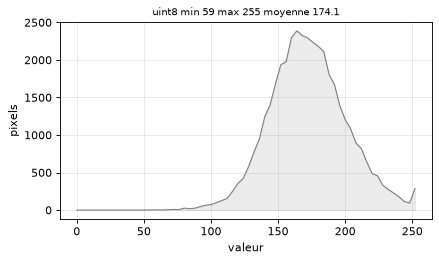

In [13]:
def channel_stats(images):  # moyenne et ecart-type par canal sur un ensemble d'images ; renvoie deux listes
    total, total_sq, n = 0.0, 0.0, 0  # sommes des valeurs, sommes des carres, nombre de pixels
    for image in images:  # pour chaque image (images peut etre un generateur : lues une a une)
        # valeurs ramenees a [0, 1], en float64 pour des sommes precises
        x = image.astype(np.float64) / (65535.0 if image.dtype == np.uint16 else 255.0)
        x = x[..., None] if x.ndim == 2 else x  # image grise : ajoute un axe canal (H, W, 1)
        # cumule par canal : somme des valeurs, somme des carres, nombre de pixels (H x W)
        total, total_sq, n = total + x.sum(axis=(0, 1)), total_sq + (x**2).sum(axis=(0, 1)), n + x.shape[0] * x.shape[1]
    mean = total / n  # moyenne = somme / nombre
    # ecart-type = racine(moyenne des carres - carre de la moyenne) ; maximum evite une racine negative
    return mean.round(4).tolist(), np.sqrt(np.maximum(total_sq / n - mean**2, 1e-12)).round(4).tolist()


# STATS_IMAGES images du TRAIN tirees au hasard (graine fixe)
train_paths = neu_split[neu_split["split"] == "train"].sample(n=STATS_IMAGES, random_state=SEED)["path"]
# statistiques apres le pretraitement (gris, 128 x 128, INTER_AREA), images lues une a une
mean, std = channel_stats(cv2.resize(read_image(p, "gray"), (128, 128), interpolation=cv2.INTER_AREA) for p in train_paths)
# a comparer avec ImageNet
print("NEU-CLS train (gris, 128 px) : moyenne", mean, "ecart-type", std, "| ImageNet : 0.449 / 0.226 en moyenne des canaux")
viz.histogram(read_image(train_paths.iloc[0], "gray"), bins=64)  # histogramme des niveaux de gris d'une image (64 barres)

## 11. Resultats

In [14]:
pd.DataFrame(  # tableau recapitulatif, une ligne par jeu (dernier objet de la cellule : affiche)
    [  # liste des lignes
        {  # ligne NEU-CLS
            "jeu": "NEU-CLS",  # nom du jeu
            "images": len(neu_split),  # nombre d'images
            "decoupage": "stratifie",  # strategie de decoupage
            **neu_split["split"].value_counts().to_dict(),  # ** recopie ici le dictionnaire {partie: nombre d'images}
            "groupes coupes": crossing_groups(neu_split),  # doit valoir 0
        },
        {  # ligne Magnetic Tile
            "jeu": "Magnetic Tile",  # nom du jeu
            "images": len(tiles_split),  # nombre d'images
            "decoupage": "groupe",  # strategie de decoupage
            **tiles_split["split"].value_counts().to_dict(),  # nombre d'images par partie
            "groupes coupes": crossing_groups(tiles_split),  # doit valoir 0
        },
        {  # ligne du jeu fictif
            "jeu": "fictif",  # nom du jeu
            "images": len(fictive),  # nombre d'images
            "decoupage": "temporel",  # strategie de decoupage
            **fictive["split"].value_counts().to_dict(),  # nombre d'images par partie
            "groupes coupes": crossing_groups(fictive),  # doit valoir 0
        },
    ]
)

,jeu,images,decoupage,train,val,test,groupes coupes
0,NEU-CLS,1800,stratifie,1260,270,270,0
1,Magnetic Tile,1344,groupe,860,215,269,0
2,fictif,340,temporel,231,57,52,0


## 12. Passer en production

Les memes choix en YAML (section `data` et `split` de n'importe quelle recette) :

```yaml
data: {root: data/raw/neu_cls_flat, layout: class_folders, color: rgb}
split: {file: outputs/classification/split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}

data: {root: data/raw/magnetic_tile, layout: image_mask, extensions: [".jpg"], groups_csv: outputs/explore/magnetic_tile/groups.csv}
split: {file: outputs/segmentation/tile_split.csv, strategy: grouped, val_fraction: 0.15, test_fraction: 0.2}

data: {..., group_regex: "^(C\\d+)_", timestamp_regex: "_(?P<Y>\\d{4})(?P<m>\\d{2})(?P<d>\\d{2})_"}
split: {strategy: temporal}
```

`python recipes/<tache>/scripts/prepare.py --config <yaml>` ecrit le `split.csv`. Controle : les
fonctions de production (`vtb.io.catalogs.build_catalog`, `vtb.split.make_split`) donnent
exactement les memes decoupages que les cellules de ce notebook.

In [15]:
from vtb.core.config import DataConfig, SplitConfig  # configurations de la toolbox (sections data et split du YAML)
from vtb.io.catalogs import build_catalog  # construit le catalogue d'apres la config data
from vtb.split import make_split  # decoupe d'apres la config split


def same_split(ours, theirs):  # part des images rangees dans la meme partie par deux decoupages ; renvoie un nombre entre 0 et 1
    a = ours.set_index("path")["split"]  # serie path -> split de notre decoupage
    # aligne l'autre decoupage sur nos chemins (reindex) et compte les accords
    return float((a == theirs.set_index("path")["split"].reindex(a.index)).mean())


# decoupage de production de NEU-CLS (dossier par classe, stratifie)
prod_neu = make_split(build_catalog(DataConfig(root=str(DATA_DIR))), SplitConfig(strategy="stratified"), SEED)
print(f"NEU-CLS stratifie : {same_split(neu_split, prod_neu):.1%} des images dans le meme sous-ensemble que vtb")  # doit afficher 100 %
data = DataConfig(  # config data de Magnetic Tile, comme dans le YAML
    root=str(TILE_DIR),  # dossier du jeu
    layout="image_mask",  # rangement image + masque a cote
    extensions=[".jpg"],  # seules les .jpg sont des images (les .png sont les masques)
    groups_csv=str(TILE_GROUPS_CSV) if TILE_GROUPS_CSV.exists() else None,  # CSV des groupes s'il existe, sinon pas de groupe
)
# decoupage groupe de production, memes fractions que plus haut
prod_tiles = make_split(build_catalog(data), SplitConfig(strategy="grouped", val_fraction=0.15, test_fraction=0.2), SEED)
print(f"Magnetic Tile groupe : {same_split(tiles_split, prod_tiles):.1%} identique a vtb")  # doit afficher 100 %
# pour chaque decoupage ecrit par une recette
for recipe in (Path("outputs/classification/split.csv"), Path("outputs/segmentation/tile_split.csv")):
    if recipe.exists():  # si la recette a ete lancee
        ours = neu_split if "classification" in str(recipe) else tiles_split  # notre decoupage correspondant
        # pourcentage d'accord avec la recette
        print(f"{recipe} : {same_split(ours, pd.read_csv(recipe, keep_default_na=False)):.1%} identique")

NEU-CLS stratifie : 100.0% des images dans le meme sous-ensemble que vtb


Magnetic Tile groupe : 100.0% identique a vtb
outputs/classification/split.csv : 100.0% identique
outputs/segmentation/tile_split.csv : 100.0% identique
